# Chapter 2 — Rigid motion and Lie groups

Companion notebook to **Chapter 2** of the course notes. Every cell checks a statement of the chapter numerically with
`vslam.lie`, then the last section reproduces the "banana" of Figure 2.1.

Conventions: twists are $\boldsymbol\xi = (\boldsymbol\rho, \boldsymbol\phi)$ (translation first) and perturbations are
on the **right**, $T \oplus \boldsymbol\tau = T\,\mathrm{Exp}(\boldsymbol\tau)$.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent            # the code/ directory
sys.path[:0] = [str(ROOT), str(ROOT / "examples")]

import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
from scipy.linalg import expm
from vslam import lie
import ch02_banana as banana

rng = np.random.default_rng(0)
# after the imports: the example scripts select the Agg backend
%matplotlib inline

## 1. The hat operator (Lemma 2.3)

In [2]:
a, b = rng.normal(size=3), rng.normal(size=3)
K = lie.hat(a)
print("(i)   hat(a) b == a x b          :", np.allclose(K @ b, np.cross(a, b)))
print("(ii)  hat(a)^2 == a a^T - |a|^2 I :", np.allclose(K @ K, np.outer(a, a) - a @ a * np.eye(3)))
print("(iii) hat(a)^3 == -|a|^2 hat(a)   :", np.allclose(K @ K @ K, -(a @ a) * K))
R = lie.so3_exp(rng.normal(size=3))
print("(v)   R hat(a) R^T == hat(R a)    :", np.allclose(R @ K @ R.T, lie.hat(R @ a)))

(i)   hat(a) b == a x b          : True
(ii)  hat(a)^2 == a a^T - |a|^2 I : True
(iii) hat(a)^3 == -|a|^2 hat(a)   : True
(v)   R hat(a) R^T == hat(R a)    : True


## 2. Rodrigues' formula and the logarithm (Theorem 2.5, Proposition 2.6)

`so3_exp` uses the closed form; we compare it with SciPy's general matrix exponential, including the awkward angles
near $0$ and near $\pi$ where the code switches to Taylor series or to the symmetric part of $R$.

In [3]:
axis = rng.normal(size=3); axis /= np.linalg.norm(axis)
print(f"{'theta':>12} {'|Exp - expm|':>14} {'|Log(Exp(phi)) - phi|':>22}")
for theta in [0.0, 1e-9, 1e-4, 0.5, 2.0, np.pi - 1e-4, np.pi - 1e-9]:
    phi = theta * axis
    R = lie.so3_exp(phi)
    print(f"{theta:12.3e} {np.abs(R - expm(lie.hat(phi))).max():14.1e} "
          f"{np.abs(lie.so3_log(R) - phi).max():22.1e}")

       theta   |Exp - expm|  |Log(Exp(phi)) - phi|
   0.000e+00        0.0e+00                0.0e+00
   1.000e-09        0.0e+00                0.0e+00
   1.000e-04        1.4e-20                0.0e+00
   5.000e-01        1.1e-16                1.7e-18
   2.000e+00        4.4e-16                2.8e-17
   3.141e+00        2.2e-16                7.0e-08
   3.142e+00        2.2e-16                1.2e-08


**Geometric meaning.** $\mathrm{Exp}(\theta\mathbf a)$ fixes the axis and turns the orthogonal plane by $\theta$:

In [4]:
theta = 0.7
R = lie.so3_exp(theta * axis)
b = np.cross(axis, rng.normal(size=3)); b /= np.linalg.norm(b)   # unit vector orthogonal to the axis
print("R a == a                          :", np.allclose(R @ axis, axis))
print("angle between b and R b           :", np.arccos(b @ R @ b), "(expected", theta, ")")
print("trace formula cos(theta)          :", 0.5 * (np.trace(R) - 1), "vs", np.cos(theta))

R a == a                          : True
angle between b and R b           : 0.6999999999999998 (expected 0.7 )
trace formula cos(theta)          : 0.7648421872844884 vs 0.7648421872844885


## 3. The exponential of SE(3) is a screw motion (Theorem 2.8)

A mower driving at $v$ with yaw rate $\omega$ for one second has twist $\boldsymbol\xi = (v,0,0,\;0,0,\omega)$.
$\mathrm{Exp}(t\boldsymbol\xi)$, $t\in[0,1]$, traces a circular arc; its endpoint is $J_l(\boldsymbol\phi)\boldsymbol\rho$, **not**
$\boldsymbol\rho$. Compare with the closed form of Exercise 2.2: $\frac v\omega(\sin\omega,\ 1-\cos\omega)$.

endpoint from Exp       : [1.5534 1.0627]
closed form (Ex. 2.2)   : [1.5534 1.0627]
naive 'translation=rho' : [2. 0.]


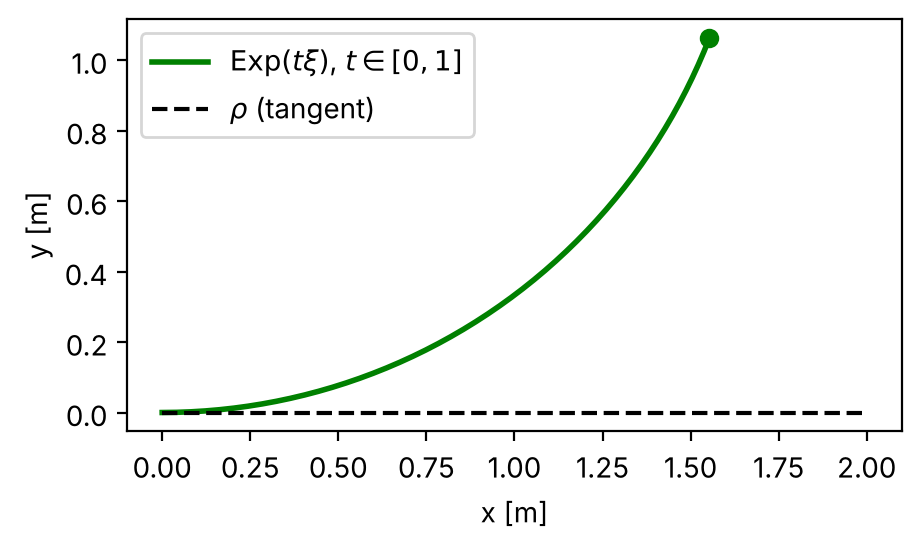

In [5]:
v, w = 2.0, 1.2
xi = np.array([v, 0, 0, 0, 0, w])
ts = np.linspace(0, 1, 50)
path = np.array([lie.se3_exp(t * xi)[:3, 3] for t in ts])

end = lie.se3_exp(xi)[:3, 3]
print("endpoint from Exp       :", end[:2])
print("closed form (Ex. 2.2)   :", v / w * np.array([np.sin(w), 1 - np.cos(w)]))
print("naive 'translation=rho' :", xi[:2])

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(path[:, 0], path[:, 1], "g", lw=2, label=r"$\mathrm{Exp}(t\xi)$, $t\in[0,1]$")
ax.plot([0, v], [0, 0], "k--", label=r"$\rho$ (tangent)")
ax.plot(*end[:2], "go"); ax.set_aspect("equal"); ax.legend(); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]");

## 4. The adjoint (Proposition 2.9)

In [6]:
T, xi = lie.se3_exp(rng.normal(size=6)), rng.normal(size=6)
Ad = lie.se3_adjoint(T)
print("T hat(xi) T^-1 == hat(Ad xi)      :", np.allclose(T @ lie.se3_hat(xi) @ lie.se3_inv(T), lie.se3_hat(Ad @ xi)))
print("T Exp(xi) T^-1 == Exp(Ad xi)      :", np.allclose(T @ lie.se3_exp(xi) @ lie.se3_inv(T), lie.se3_exp(Ad @ xi)))
print("det(Ad) == 1 (Exercise 2.4)       :", np.isclose(np.linalg.det(Ad), 1.0))
print("Ad orthogonal?                    :", np.allclose(Ad.T @ Ad, np.eye(6)))

T hat(xi) T^-1 == hat(Ad xi)      : True
T Exp(xi) T^-1 == Exp(Ad xi)      : True
det(Ad) == 1 (Exercise 2.4)       : True
Ad orthogonal?                    : False


## 5. Jacobians against finite differences (Theorem 2.12, Proposition 2.14)

A tiny helper computes right Jacobians numerically; every analytic formula of the chapter should match it to ~$10^{-8}$.

In [7]:
def num_jac(f, x, plus, minus, n, eps=1e-6):
    """Central-difference Jacobian of f at x with generic plus/minus operations."""
    fx = f(x)
    cols = []
    for i in range(n):
        d = np.zeros(n); d[i] = eps
        cols.append((minus(f(plus(x, d)), fx) - minus(f(plus(x, -d)), fx)) / (2 * eps))
    return np.column_stack(cols)

vec_plus, vec_minus = (lambda x, d: x + d), (lambda a, b: a - b)
so3_minus = lambda R1, R0: lie.so3_log(R0.T @ R1)
se3_plus = lambda T, d: T @ lie.se3_exp(d)

phi = rng.normal(size=3)
J_num = num_jac(lie.so3_exp, phi, vec_plus, so3_minus, 3)
print("J_r(phi)        error:", np.abs(J_num - lie.so3_right_jacobian(phi)).max())

T, p = lie.se3_exp(rng.normal(size=6)), rng.normal(size=3)
J_num = num_jac(lambda X: lie.se3_act(X, p), T, se3_plus, vec_minus, 6)
print("d(Tp)/dxi       error:", np.abs(J_num - lie.jac_act(T, p)[0]).max())

J_r(phi)        error: 5.901557020848713e-11
d(Tp)/dxi       error: 1.335231925025937e-10


**Exercise 2.3, checked.** For the world-to-camera transform $\mathbf q = T_{wc}^{-1}\mathbf p_w$ the chapter claims
$\partial\mathbf q/\partial\boldsymbol\xi = [\,-I\ \ \mathbf q^\wedge\,]$:

In [8]:
f = lambda X: lie.se3_act(lie.se3_inv(X), p)
J_num = num_jac(f, T, se3_plus, vec_minus, 6)
q = f(T)
J_ana = np.hstack([-np.eye(3), lie.hat(q)])
print("error:", np.abs(J_num - J_ana).max())

error: 1.397779669787269e-10


## 6. The banana (Proposition 2.16, Figure 2.1)

The mower compounds noisy odometry steps $T_k = T_{k-1}U\,\mathrm{Exp}(\boldsymbol\epsilon_k)$. We compare Monte Carlo with the
Lie-algebra Gaussian propagated by $\Sigma_k = \mathrm{Ad}_{U^{-1}}\Sigma_{k-1}\mathrm{Ad}_{U^{-1}}^\top + Q$.
(Fewer samples than the script, to keep the notebook fast.)

std propagated : [0.189 1.569 0.005 0.001 0.001 0.367]
std Monte Carlo: [0.237 1.541 0.006 0.001 0.001 0.362]


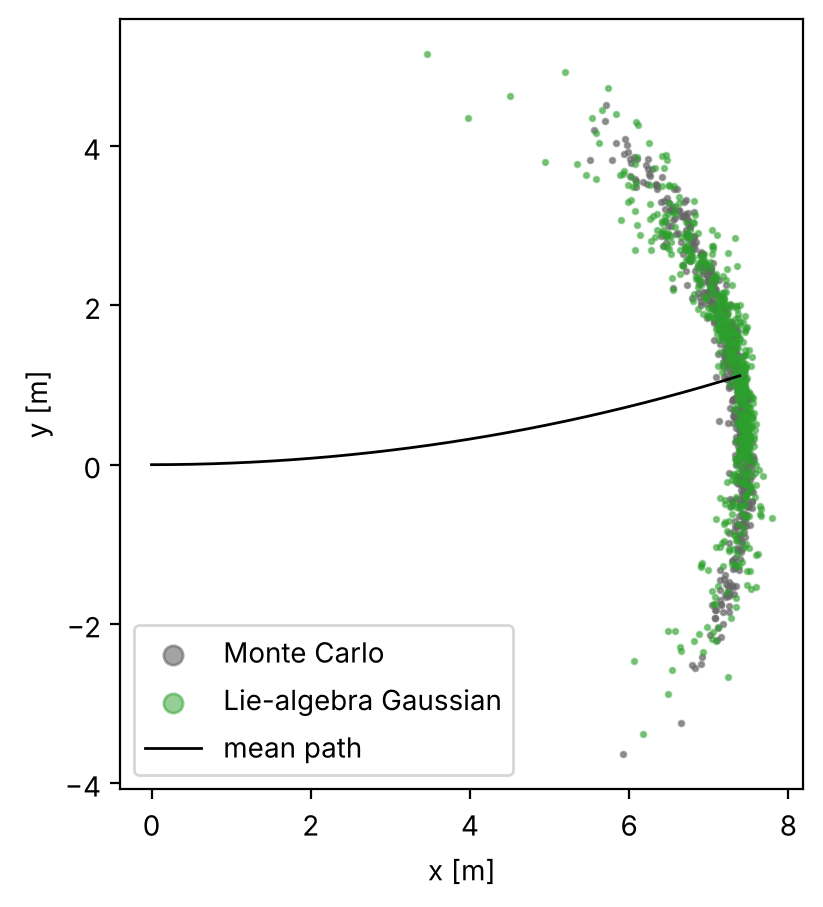

In [9]:
banana.N_SAMPLES = 600

mc = banana.monte_carlo(np.random.default_rng(1))
T_bar, Sigma, path = banana.propagate()
lie_xy = np.array([(T_bar @ lie.se3_exp(e))[:2, 3]
                   for e in rng.multivariate_normal(np.zeros(6), Sigma, 600)])

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(mc[:, 0, 3], mc[:, 1, 3], s=3, color="0.4", alpha=0.6, label="Monte Carlo")
ax.scatter(lie_xy[:, 0], lie_xy[:, 1], s=3, color="tab:green", alpha=0.5, label="Lie-algebra Gaussian")
ax.plot(path[:, 0], path[:, 1], "k", lw=1, label="mean path")
ax.set_aspect("equal"); ax.legend(markerscale=4); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]");

xi_mc = np.array([lie.se3_log(lie.se3_inv(T_bar) @ T) for T in mc])
print("std propagated :", np.sqrt(np.diag(Sigma)).round(3))
print("std Monte Carlo:", xi_mc.std(axis=0).round(3))

## 7. Try it yourself

* Halve the yaw noise (`banana.SIGMAS[5]`). Does the first-order rule now match Monte Carlo along the forward axis too?
* Express the final covariance in the **left** (world-frame) convention with $\mathrm{Ad}_{\bar T}\Sigma\mathrm{Ad}_{\bar T}^\top$
  (Proposition 2.16 (i)). Which blocks change, and why?
* Mount a camera 0.8 m ahead of the mower's centre ($T_{bc}$ a pure translation) and propagate its uncertainty.
  Compare with the body's (Exercise 2.4).